### REFERENCES
 * https://chatgpt.com

# Problem Framing

> ## Main goal
 > The main goal of this project is to predict the financial health of small businesses using numeric and categorical features derived from financial, operational, and behavioral data.
> The target variable, Financial Health Index (FHI), can be used as either:
> A continuous score representing overall financial health, or a categorical class for classification tasks.
> This prediction helps businesses, banks, and policymakers make data-driven decisions to reduce financial risk and improve support strategies.

> ## Value
 > * Assess business health efficiently at scale
 > * Identify at-risk businesses for targeted interventions
 > * Optimize financial products and services based on predicted risk and needs
 > * Improve resource allocation by focusing on businesses needing support
> 
> Even small improvements in prediction accuracy or F1-score can significantly reduce financial risk exposure and improve support outcomes.

> ## Can we solve it without ML?
> Rule-based approaches (e.g., thresholds on revenue or profit margin) are simple but limited. ML allows:
> 
> * Capturing complex interactions between multiple financial and operational metrics
> * Modeling non-linear relationships (e.g., turnover vs. expenses vs. profit margin)
> * Automatic adaptation to changing business conditions
> * Better predictive performance for both continuous FHI and categorical classes



> ## The dataset
> The dataset contains information on businesses’ finances, operations, demographics, and attitudes. Data preprocessing included:
> * Handling missing values via median imputation and missing flags
> * Encoding categorical variables using one-hot encoding
> * Scaling numeric features

> ## Technical formulation
> 
> * Problem type: Supervised learning
> * Task type: Classification (FHI categories)
> * Input features (X): Processed numeric and categorical features
> * Target variable (y): FHI class

> The model performance can be measured via:
> * F1-score for spam class: Balances precision and recall
> * ROC-AUC: for probabilistic predictions of class
> * Accuracy is secondary, especially if the dataset is imbalanced
> * Feature importance: To understand drivers of financial health


# 1. Data Collection & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.impute import SimpleImputer

import lightgbm as lgb
from lightgbm import LGBMClassifier

try:
    import xgboost as xgb
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except ImportError:
    XGB_AVAILABLE = False
    print("XGBoost not disponible — ignored")

try:
    from catboost import CatBoostClassifier
    CB_AVAILABLE = True
except ImportError:
    CB_AVAILABLE = False
    print("CatBoost non disponible — ignored")

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    OPTUNA_AVAILABLE = True
except ImportError:
    OPTUNA_AVAILABLE = False
    print("Optuna not disponible - ignored")

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [2]:
# Load data
train_df = pd.read_csv("Train.csv")
test_df  = pd.read_csv("Test.csv")

print(f"Train : {train_df.shape}  |  Test : {test_df.shape}")
print("\nTarget distribution (train):")
print(train_df['Target'].value_counts())
print("\nTarget distribution (%) :")
print(train_df['Target'].value_counts(normalize=True).round(3)*100)

Train : (9618, 39)  |  Test : (2405, 38)

Target distribution (train):
Target
Low       6280
Medium    2868
High       470
Name: count, dtype: int64

Target distribution (%) :
Target
Low       65.3
Medium    29.8
High       4.9
Name: proportion, dtype: float64


# 2. EDA — Exploratory Data Analysis

In [3]:
# Data overview
print("=" * 60)
print("OVERVIEW")
print("=" * 60)
print("\nTypes & missing values :")
info = pd.DataFrame({
    'dtype': train_df.dtypes,
    'null_count': train_df.isnull().sum(),
    'null_pct': (train_df.isnull().mean() * 100).round(2)
})
print(info[info['null_count'] > 0].sort_values('null_pct', ascending=False).to_string())

OVERVIEW

Types & missing values :
                                                                    dtype  null_count  null_pct
uses_informal_lender                                               object        4489     46.67
uses_friends_family_savings                                        object        4488     46.66
motivation_make_more_money                                         object        4291     44.61
funeral_insurance                                                  object        4188     43.54
medical_insurance                                                  object        4188     43.54
business_age_months                                               float64        4111     42.74
future_risk_theft_stock                                            object        4100     42.63
has_debit_card                                                     object        4003     41.62
has_internet_banking                                               object        4003     41.62
has_l

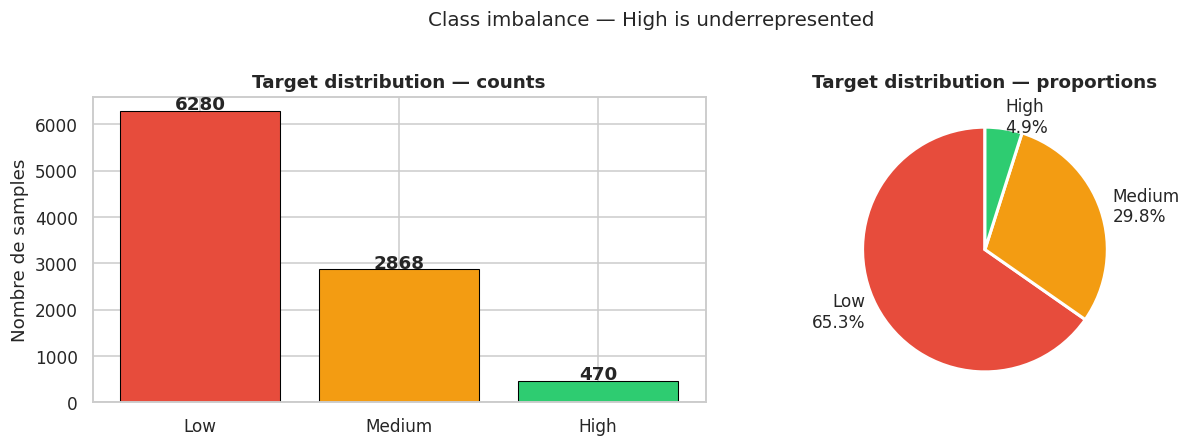

In [4]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

order = ['Low', 'Medium', 'High']
colors = ['#e74c3c', '#f39c12', '#2ecc71']

counts = train_df['Target'].value_counts()[order]
axes[0].bar(order, counts, color=colors, edgecolor='black', linewidth=0.7)
axes[0].set_title('Target distribution — counts', fontweight='bold')
axes[0].set_ylabel('Nombre de samples')
for i, v in enumerate(counts):
    axes[0].text(i, v + 30, str(v), ha='center', fontweight='bold')

pcts = (counts / counts.sum() * 100).round(1)
axes[1].pie(pcts, labels=[f"{o}\n{p}%" for o, p in zip(order, pcts)],
            colors=colors, autopct='', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Target distribution — proportions', fontweight='bold')

plt.suptitle('Class imbalance — High is underrepresented', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

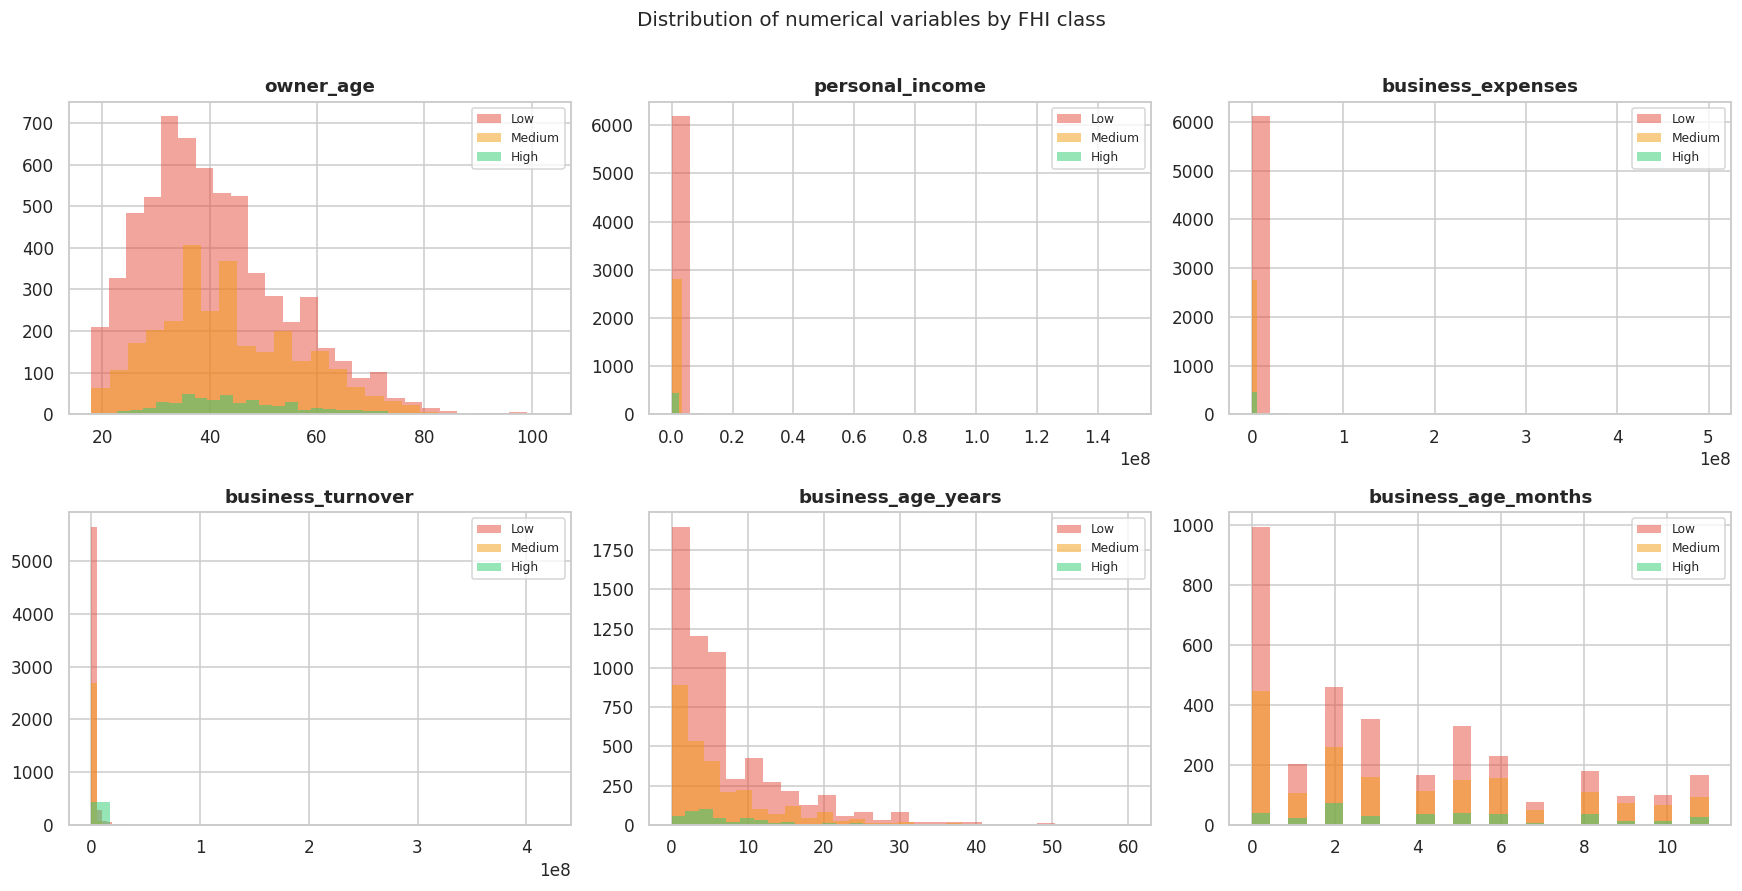

In [5]:
#  Distribution of numeric features by class
num_cols = ['owner_age', 'personal_income', 'business_expenses', 'business_turnover',
            'business_age_years', 'business_age_months']
num_cols = [c for c in num_cols if c in train_df.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

palette = {'Low': '#e74c3c', 'Medium': '#f39c12', 'High': '#2ecc71'}

for i, col in enumerate(num_cols[:6]):
    for cls in ['Low', 'Medium', 'High']:
        vals = train_df.loc[train_df['Target'] == cls, col].dropna()
        axes[i].hist(vals, bins=25, alpha=0.5, label=cls, color=palette[cls], edgecolor='none')
    axes[i].set_title(col, fontweight='bold')
    axes[i].legend(fontsize=8)
    axes[i].set_xlabel('')

plt.suptitle('Distribution of numerical variables by FHI class', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

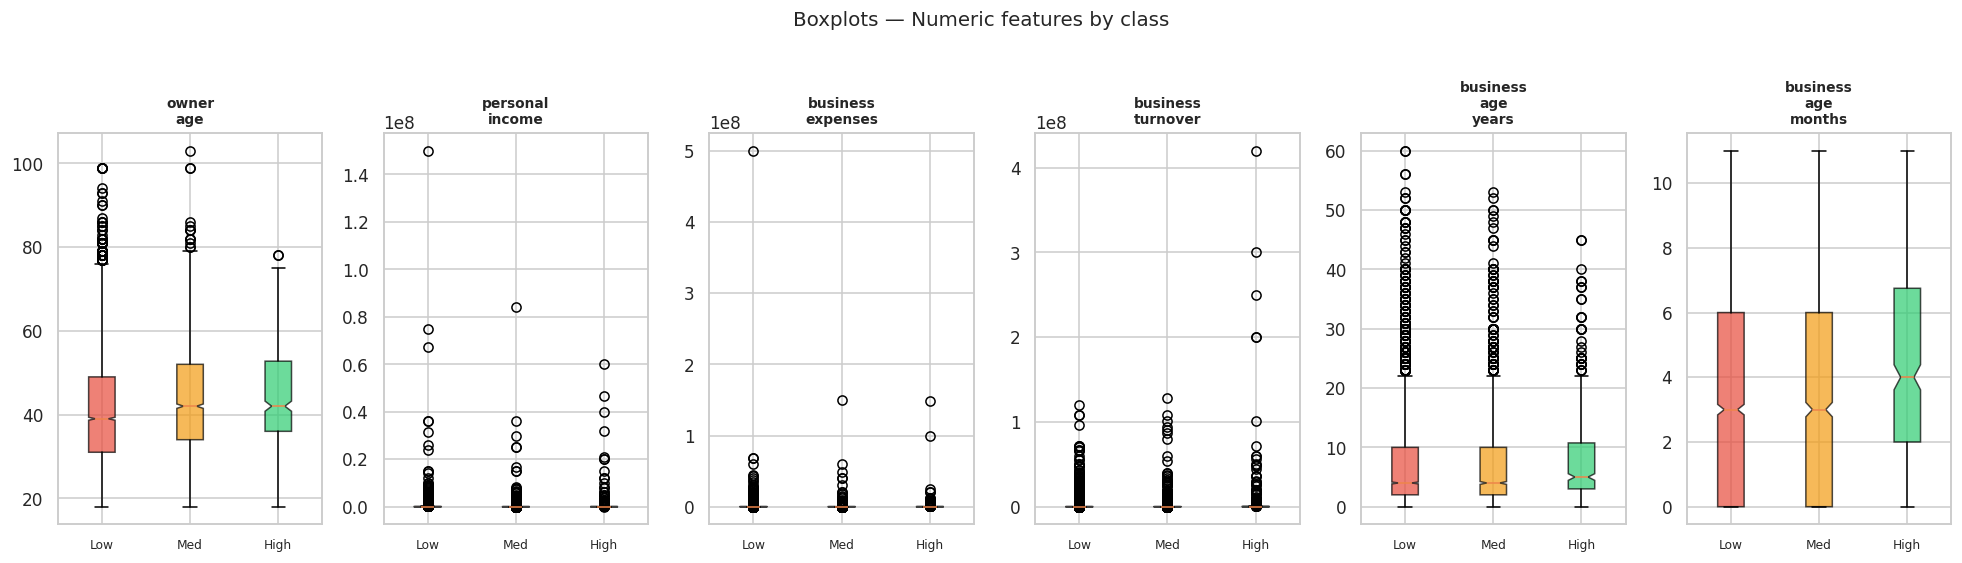

In [6]:
# Numeric boxplots by class
fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 5))

for i, col in enumerate(num_cols):
    data_to_plot = [train_df.loc[train_df['Target'] == cls, col].dropna() for cls in ['Low', 'Medium', 'High']]
    bp = axes[i].boxplot(data_to_plot, labels=['Low', 'Med', 'High'], patch_artist=True, notch=True)
    for patch, color in zip(bp['boxes'], ['#e74c3c', '#f39c12', '#2ecc71']):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[i].set_title(col.replace('_', '\n'), fontsize=9, fontweight='bold')
    axes[i].tick_params(axis='x', labelsize=8)

plt.suptitle('Boxplots — Numeric features by class', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

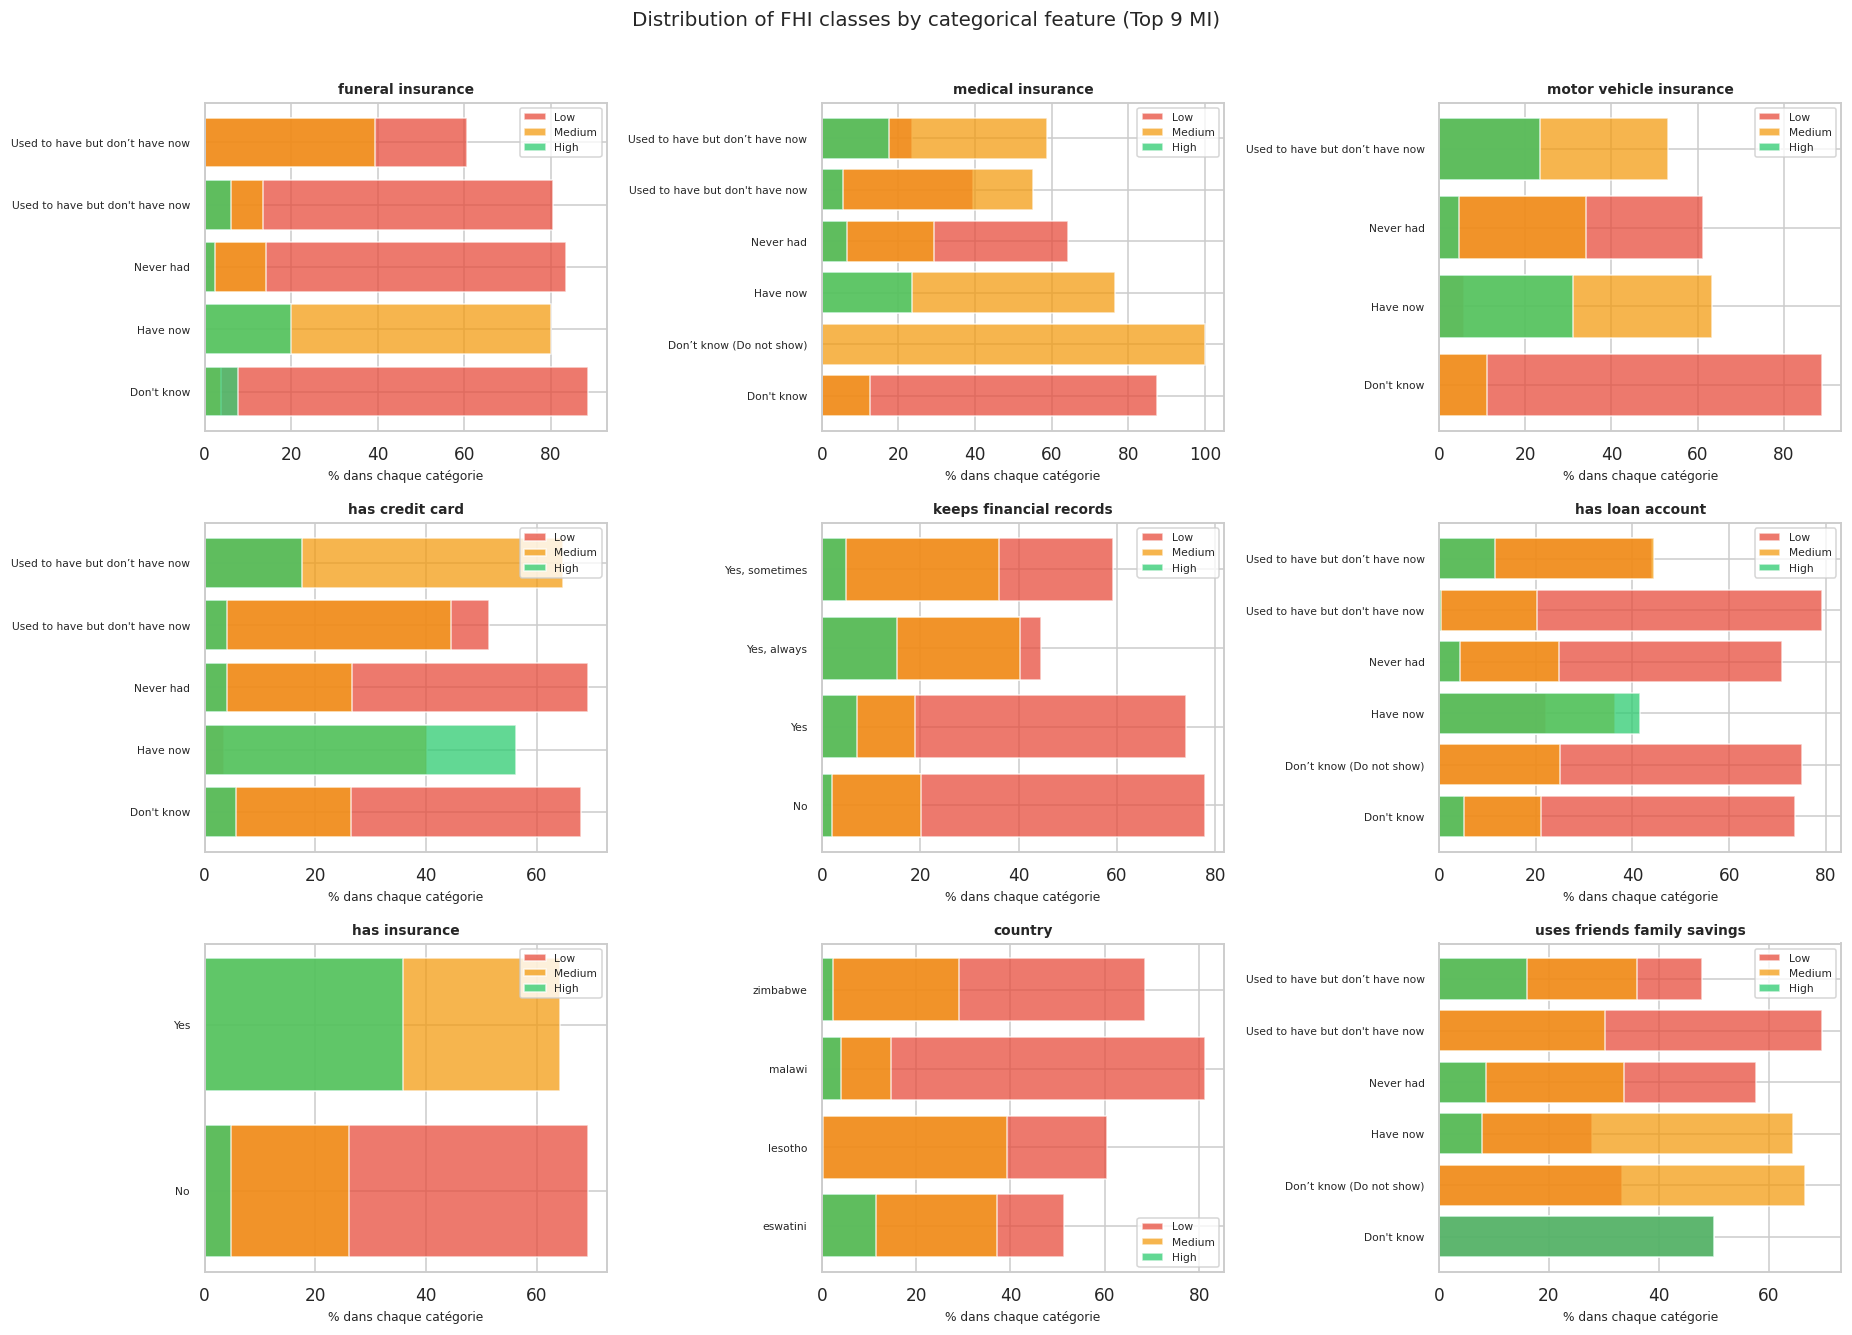

In [7]:
# Top categorical features vs Target
top_cat_cols = ['funeral_insurance', 'medical_insurance', 'motor_vehicle_insurance',
                'has_credit_card', 'keeps_financial_records', 'has_loan_account',
                'has_insurance', 'country', 'uses_friends_family_savings']
top_cat_cols = [c for c in top_cat_cols if c in train_df.columns]

fig, axes = plt.subplots(3, 3, figsize=(17, 12))
axes = axes.ravel()

for i, col in enumerate(top_cat_cols[:9]):
    ct = pd.crosstab(train_df[col], train_df['Target'], normalize='index') * 100
    for cls, clr in zip(['Low', 'Medium', 'High'], ['#e74c3c', '#f39c12', '#2ecc71']):
        if cls in ct.columns:
            axes[i].barh(ct.index.astype(str), ct[cls], label=cls, color=clr, alpha=0.75)
    axes[i].set_title(col.replace('_', ' '), fontweight='bold', fontsize=9)
    axes[i].set_xlabel('% dans chaque catégorie', fontsize=8)
    axes[i].legend(fontsize=7)
    axes[i].tick_params(axis='y', labelsize=7)

plt.suptitle('Distribution of FHI classes by categorical feature (Top 9 MI)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

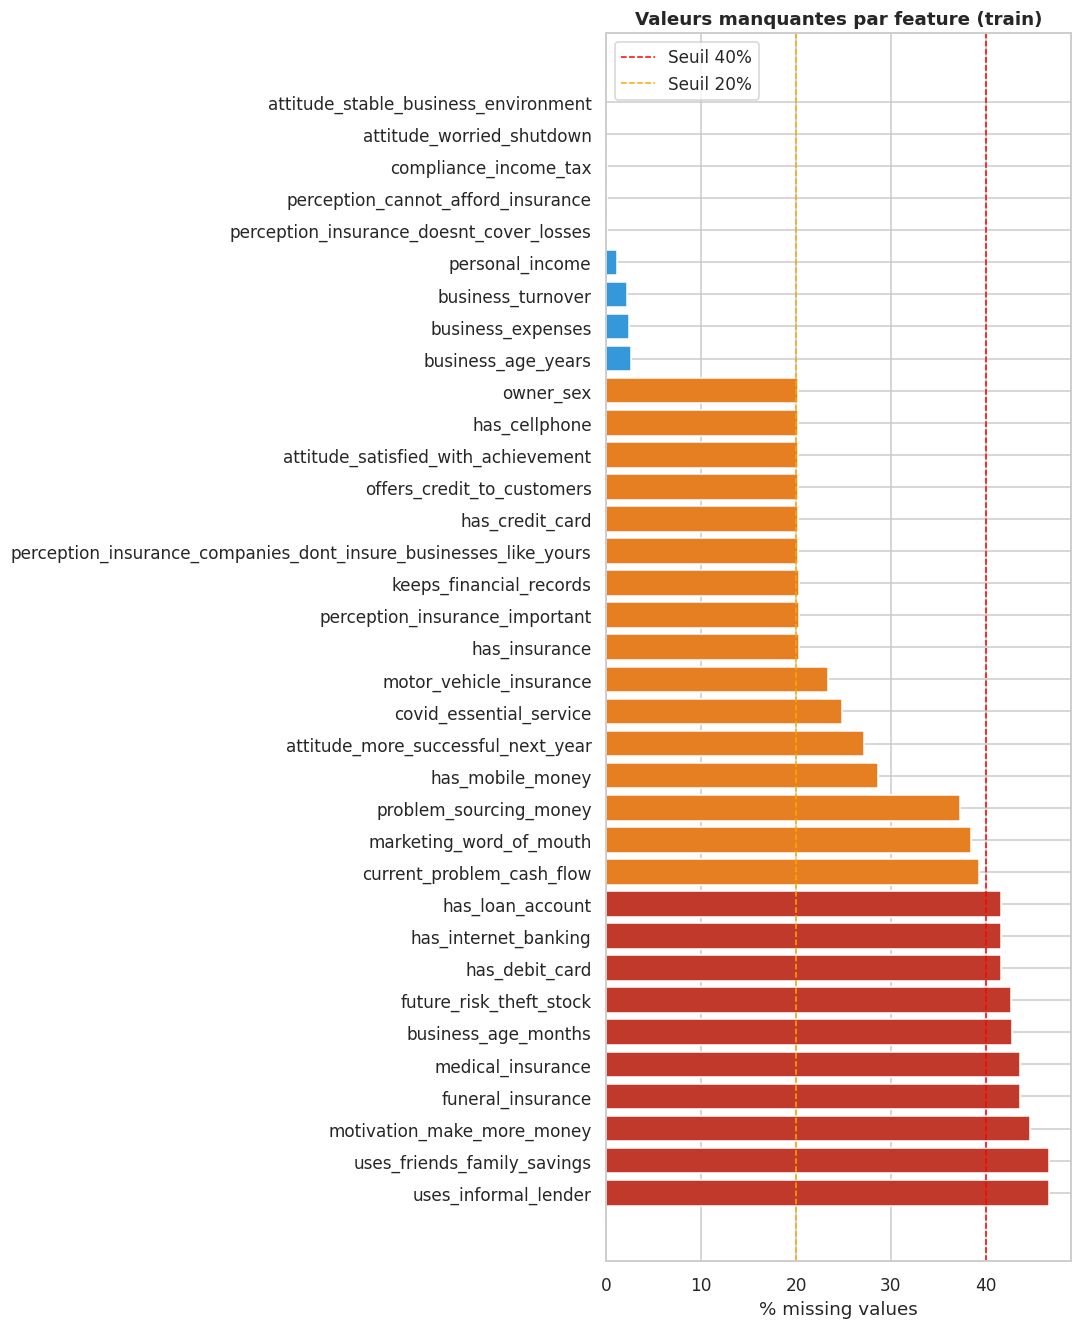

In [8]:
# Heatmap of missing values
miss_pct = train_df.isnull().mean() * 100
miss_pct = miss_pct[miss_pct > 0].sort_values(ascending=False)

if len(miss_pct) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, len(miss_pct) * 0.35)))
    colors_miss = ['#c0392b' if v > 40 else '#e67e22' if v > 20 else '#3498db' for v in miss_pct]
    ax.barh(miss_pct.index, miss_pct.values, color=colors_miss)
    ax.axvline(40, color='red', linestyle='--', linewidth=1, label='Seuil 40%')
    ax.axvline(20, color='orange', linestyle='--', linewidth=1, label='Seuil 20%')
    ax.set_xlabel('% missing values')
    ax.set_title('Valeurs manquantes par feature (train)', fontweight='bold')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No missing values.")

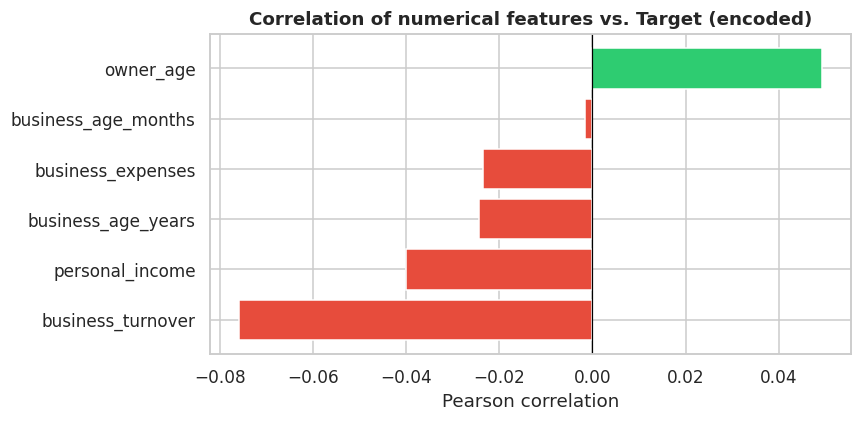

In [9]:
# Numeric correlation → Target
le_tmp = LabelEncoder()
y_enc_tmp = le_tmp.fit_transform(train_df['Target'])

num_corr = train_df[num_cols].corrwith(pd.Series(y_enc_tmp, index=train_df.index)).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
colors_corr = ['#e74c3c' if v < 0 else '#2ecc71' for v in num_corr]
ax.barh(num_corr.index, num_corr.values, color=colors_corr)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Correlation of numerical features vs. Target (encoded)', fontweight='bold')
ax.set_xlabel('Pearson correlation')
plt.tight_layout()
plt.show()

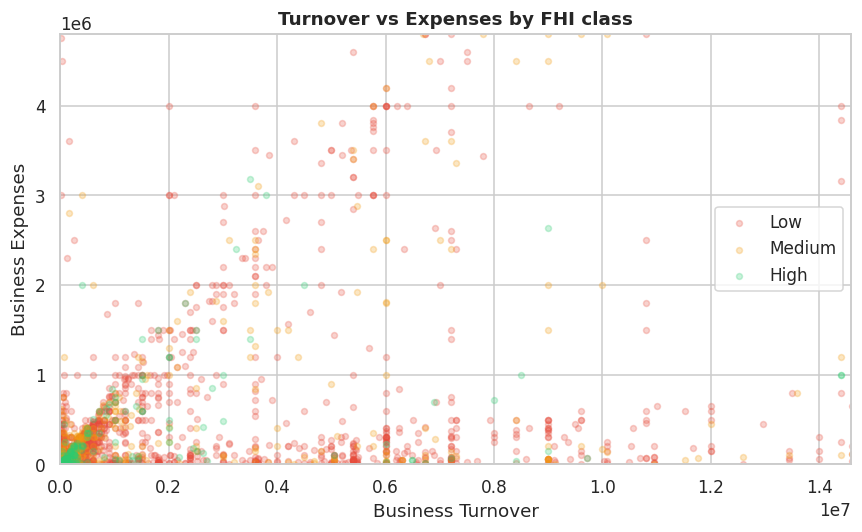

In [10]:
# Scatterplot : Turnover vs Expenses
if 'business_turnover' in train_df.columns and 'business_expenses' in train_df.columns:
    fig, ax = plt.subplots(figsize=(8, 5))
    for cls, clr in zip(['Low', 'Medium', 'High'], ['#e74c3c', '#f39c12', '#2ecc71']):
        sub = train_df[train_df['Target'] == cls]
        ax.scatter(sub['business_turnover'], sub['business_expenses'],
                   alpha=0.25, s=15, label=cls, color=clr)
    ax.set_xlim(0, train_df['business_turnover'].quantile(0.98))
    ax.set_ylim(0, train_df['business_expenses'].quantile(0.98))
    ax.set_xlabel('Business Turnover')
    ax.set_ylabel('Business Expenses')
    ax.set_title('Turnover vs Expenses by FHI class', fontweight='bold')
    ax.legend()
    plt.tight_layout()
    plt.show()

# 3. Data Preprocessing

In [11]:
# Columns definition
TARGET = 'Target'
ID_COL = 'ID'

all_cols = [c for c in train_df.columns if c not in [TARGET, ID_COL]]

numerical_cols = train_df[all_cols].select_dtypes(include=['float64', 'int64']).columns.tolist()
categorical_cols = train_df[all_cols].select_dtypes(include='object').columns.tolist()

print(f"Numeric ({len(numerical_cols)}) : {numerical_cols}")
print(f"\nCategorical ({len(categorical_cols)}) : {categorical_cols}")

Numeric (6) : ['owner_age', 'personal_income', 'business_expenses', 'business_turnover', 'business_age_years', 'business_age_months']

Categorical (31) : ['country', 'attitude_stable_business_environment', 'attitude_worried_shutdown', 'compliance_income_tax', 'perception_insurance_doesnt_cover_losses', 'perception_cannot_afford_insurance', 'motor_vehicle_insurance', 'has_mobile_money', 'current_problem_cash_flow', 'has_cellphone', 'owner_sex', 'offers_credit_to_customers', 'attitude_satisfied_with_achievement', 'has_credit_card', 'keeps_financial_records', 'perception_insurance_companies_dont_insure_businesses_like_yours', 'perception_insurance_important', 'has_insurance', 'covid_essential_service', 'attitude_more_successful_next_year', 'problem_sourcing_money', 'marketing_word_of_mouth', 'has_loan_account', 'has_internet_banking', 'has_debit_card', 'future_risk_theft_stock', 'medical_insurance', 'funeral_insurance', 'motivation_make_more_money', 'uses_friends_family_savings', 'uses_in

In [12]:
# Encode target
label_map = {'Low': 0, 'Medium': 1, 'High': 2}
inv_label_map = {v: k for k, v in label_map.items()}

y_all = train_df[TARGET].map(label_map).values

print("Encoded distribution:", dict(zip(*np.unique(y_all, return_counts=True))))

Encoded distribution: {np.int64(0): np.int64(6280), np.int64(1): np.int64(2868), np.int64(2): np.int64(470)}


In [13]:
# Clean and normalize categorical features
def normalize_cat_col(series):
    s = series.astype(str).str.lower().str.strip()
    # Standardize variants 'don?t know' → 'dont_know'
    s = s.str.replace(r"don[?'\u2019]t know(?: or n/a)?", "dont_know", regex=True)
    s = s.str.replace(r"[^a-z0-9_\s]", "", regex=True)
    s = s.str.replace(r"\s+", "_", regex=True)
    s = s.replace('nan', np.nan)
    return s

for col in categorical_cols:
    train_df[col] = normalize_cat_col(train_df[col])
    test_df[col]  = normalize_cat_col(test_df[col])

print("e.g : 'funeral_insurance' after normalization :")
print(train_df['funeral_insurance'].value_counts().head(6))

e.g : 'funeral_insurance' after normalization :
funeral_insurance
never_had                         3615
have_now                          1608
used_to_have_but_dont_have_now     181
dont_know                           26
Name: count, dtype: int64


In [14]:
# Numeric imputation + missing indicator

# Indicators of missing values ​​for columns with high NaN content
high_miss_num = [c for c in numerical_cols if train_df[c].isnull().mean() > 0.10]

for col in high_miss_num:
    train_df[f'{col}_missing'] = train_df[col].isnull().astype(int)
    test_df[f'{col}_missing']  = test_df[col].isnull().astype(int)

# Imputation by median on train, applied to the test
medians = train_df[numerical_cols].median()
train_df[numerical_cols] = train_df[numerical_cols].fillna(medians)
test_df[numerical_cols]  = test_df[numerical_cols].fillna(medians)

# Indicators of deficiency for important categorical variables
high_miss_cat = [c for c in categorical_cols if train_df[c].isnull().mean() > 0.10]
for col in high_miss_cat:
    train_df[f'{col}_missing'] = train_df[col].isnull().astype(int)
    test_df[f'{col}_missing']  = test_df[col].isnull().astype(int)

# Allocate the categorical by mode
modes = train_df[categorical_cols].mode().iloc[0]
train_df[categorical_cols] = train_df[categorical_cols].fillna(modes)
test_df[categorical_cols]  = test_df[categorical_cols].fillna(modes)

print("Imputation done.")
print(f"Nouvelles colonnes indicateurs : {[c for c in train_df.columns if c.endswith('_missing')]}")

Imputation done.
Nouvelles colonnes indicateurs : ['business_age_months_missing', 'motor_vehicle_insurance_missing', 'has_mobile_money_missing', 'current_problem_cash_flow_missing', 'has_cellphone_missing', 'owner_sex_missing', 'offers_credit_to_customers_missing', 'attitude_satisfied_with_achievement_missing', 'has_credit_card_missing', 'keeps_financial_records_missing', 'perception_insurance_companies_dont_insure_businesses_like_yours_missing', 'perception_insurance_important_missing', 'has_insurance_missing', 'covid_essential_service_missing', 'attitude_more_successful_next_year_missing', 'problem_sourcing_money_missing', 'marketing_word_of_mouth_missing', 'has_loan_account_missing', 'has_internet_banking_missing', 'has_debit_card_missing', 'future_risk_theft_stock_missing', 'medical_insurance_missing', 'funeral_insurance_missing', 'motivation_make_more_money_missing', 'uses_friends_family_savings_missing', 'uses_informal_lender_missing']


# 4. Feature Engineering

In [15]:
# Financial ratios
EPS = 1e-6

def add_financial_ratios(df):
    df = df.copy()
    # Ratio profit = (turnover - expenses) / turnover
    if 'business_turnover' in df.columns and 'business_expenses' in df.columns:
        df['profit_amount']   = df['business_turnover'] - df['business_expenses']
        df['profit_margin']   = df['profit_amount'] / (df['business_turnover'] + EPS)
        df['expense_ratio']   = df['business_expenses'] / (df['business_turnover'] + EPS)
        df['turnover_per_month'] = df['business_turnover'] / (df['business_age_months'].clip(1) + EPS) \
            if 'business_age_months' in df.columns else np.nan

    if 'personal_income' in df.columns and 'business_turnover' in df.columns:
        df['income_to_turnover'] = df['personal_income'] / (df['business_turnover'] + EPS)

    if 'personal_income' in df.columns and 'business_expenses' in df.columns:
        df['net_income_proxy'] = df['personal_income'] - df['business_expenses']

    return df

train_df = add_financial_ratios(train_df)
test_df  = add_financial_ratios(test_df)
print("Financial ratios added.")

Financial ratios added.


In [16]:
# Financial Inclusion Score (composite)
FINANCIAL_INCLUSION_COLS = [
    'has_credit_card', 'has_loan_account', 'has_internet_banking',
    'has_debit_card', 'has_mobile_money', 'has_insurance'
]

def encode_have_now(df, cols):
    df = df.copy()
    for col in cols:
        if col in df.columns:
            df[f'fin_{col}'] = df[col].apply(
                lambda x: 1 if str(x).lower() in ['have_now', 'yes', '1.0', '1'] else 0
            )
    score_cols = [f'fin_{c}' for c in cols if c in df.columns]
    df['financial_inclusion_score'] = df[score_cols].sum(axis=1)
    return df

train_df = encode_have_now(train_df, FINANCIAL_INCLUSION_COLS)
test_df  = encode_have_now(test_df,  FINANCIAL_INCLUSION_COLS)

INSURANCE_COLS = ['funeral_insurance', 'medical_insurance', 'motor_vehicle_insurance']
for col in INSURANCE_COLS:
    for df in [train_df, test_df]:
        if col in df.columns:
            df[f'ins_{col}'] = df[col].apply(
                lambda x: 1 if str(x).lower() == 'have_now' else 0
            )
ins_score_cols = [f'ins_{c}' for c in INSURANCE_COLS if c in train_df.columns]
train_df['insurance_score'] = train_df[ins_score_cols].sum(axis=1)
test_df['insurance_score']  = test_df[ins_score_cols].sum(axis=1)

print("financial_inclusion_score distribution:")
print(train_df.groupby('Target')['financial_inclusion_score'].mean().sort_index())

financial_inclusion_score distribution:
Target
High      2.525532
Low       0.944586
Medium    1.220363
Name: financial_inclusion_score, dtype: float64


In [17]:
# Positive attitude score (composite)
POSITIVE_ATTITUDE_COLS = [
    'attitude_stable_business_environment',   # yes = positif
    'attitude_more_successful_next_year',
    'attitude_satisfied_with_achievement',
]
NEGATIVE_ATTITUDE_COLS = [
    'attitude_worried_shutdown',              # yes = negatif
]

for col in POSITIVE_ATTITUDE_COLS:
    for df in [train_df, test_df]:
        if col in df.columns:
            df[f'pos_{col}'] = (df[col] == 'yes').astype(int)

for col in NEGATIVE_ATTITUDE_COLS:
    for df in [train_df, test_df]:
        if col in df.columns:
            df[f'neg_{col}'] = (df[col] == 'yes').astype(int)

pos_cols = [f'pos_{c}' for c in POSITIVE_ATTITUDE_COLS if c in train_df.columns]
neg_cols = [f'neg_{c}' for c in NEGATIVE_ATTITUDE_COLS if c in train_df.columns]

train_df['attitude_score'] = train_df[pos_cols].sum(axis=1) - train_df[neg_cols].sum(axis=1)
test_df['attitude_score']  = test_df[pos_cols].sum(axis=1)  - test_df[neg_cols].sum(axis=1)

print("mean attitude_score by class:")
print(train_df.groupby('Target')['attitude_score'].mean())

mean attitude_score by class:
Target
High      1.782979
Low       1.659554
Medium    1.959205
Name: attitude_score, dtype: float64


In [18]:
# Formalization/Conformity Features
COMPLIANCE_COLS = ['keeps_financial_records', 'compliance_income_tax']
for df in [train_df, test_df]:
    # Keeps financial records : 'yes,_always' ou 'yes,_sometimes'
    if 'keeps_financial_records' in df.columns:
        df['records_always'] = (df['keeps_financial_records'].str.contains('always')).astype(int)
        df['records_sometimes'] = (df['keeps_financial_records'].str.contains('sometimes')).astype(int)
    if 'compliance_income_tax' in df.columns:
        df['pays_tax'] = (df['compliance_income_tax'] == 'yes').astype(int)

# Formalization score
formality_cols = [c for c in ['records_always', 'records_sometimes', 'pays_tax'] if c in train_df.columns]
train_df['formality_score'] = train_df[formality_cols].sum(axis=1)
test_df['formality_score']  = test_df[formality_cols].sum(axis=1)

print("mean formality_score by class:")
print(train_df.groupby('Target')['formality_score'].mean())

mean formality_score by class:
Target
High      1.117021
Low       0.353185
Medium    0.594491
Name: formality_score, dtype: float64


In [19]:
# Owner age ranges
for df in [train_df, test_df]:
    df['owner_age_bin'] = pd.cut(
        df['owner_age'], bins=[0, 25, 35, 45, 55, 120],
        labels=['<25', '25-35', '35-45', '45-55', '55+'], right=False
    ).astype(str)

print("Age ranges created.")

Age ranges created.


In [20]:
# Interaction features
for df in [train_df, test_df]:
    # Interaction : inclusion financière × attitude
    df['fin_x_attitude'] = df['financial_inclusion_score'] * (df['attitude_score'] + 3)  # shift to avoid negatives
    # Interaction : log(turnover) si disponible
    if 'business_turnover' in df.columns:
        df['log_turnover'] = np.log1p(df['business_turnover'])
    if 'business_expenses' in df.columns:
        df['log_expenses'] = np.log1p(df['business_expenses'])
    if 'personal_income' in df.columns:
        df['log_income'] = np.log1p(df['personal_income'])

print("Interaction features added.")

Interaction features added.


# 5. Data Sampling & Split

In [21]:
# Columns list update
EXCLUDE = [TARGET, ID_COL]
all_feature_cols = [c for c in train_df.columns if c not in EXCLUDE]

new_numerical = [c for c in all_feature_cols if train_df[c].dtype in ['float64', 'int64', 'int32']]
new_categorical = [c for c in all_feature_cols if train_df[c].dtype == 'object']

print(f"Total features : {len(all_feature_cols)}")
print(f"  Numériques   : {len(new_numerical)}")
print(f"  Catégorielles: {len(new_categorical)}")

Total features : 94
  Numériques   : 62
  Catégorielles: 32


In [22]:
# One Hot encoding
X_all = train_df[all_feature_cols].copy()
X_test_raw = test_df[all_feature_cols].copy()

X_all_encoded = pd.get_dummies(X_all, columns=new_categorical, drop_first=False, dtype=int)
X_test_encoded = pd.get_dummies(X_test_raw, columns=new_categorical, drop_first=False, dtype=int)

X_test_encoded = X_test_encoded.reindex(columns=X_all_encoded.columns, fill_value=0)

def clean_col_names(df):
    df.columns = (
        df.columns
          .str.replace(r"[^0-9a-zA-Z_]", "_", regex=True)
          .str.replace(r"_+", "_", regex=True)
          .str.strip("_")
    )
    return df

X_all_encoded  = clean_col_names(X_all_encoded)
X_test_encoded = clean_col_names(X_test_encoded)

y_all_encoded = y_all

print(f"Shape X train (encodé) : {X_all_encoded.shape}")
print(f"Shape X test  (encodé) : {X_test_encoded.shape}")

Shape X train (encodé) : (9618, 174)
Shape X test  (encodé) : (2405, 174)


In [23]:
# Split train / test
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_all_encoded, y_all_encoded,
    test_size=0.20, random_state=SEED, stratify=y_all_encoded
)

print(f"Train : {X_train.shape}  |  Val : {X_val.shape}")
print(f"Classes train : {dict(zip(*np.unique(y_train, return_counts=True)))}")
print(f"Classes val   : {dict(zip(*np.unique(y_val, return_counts=True)))}")

Train : (7694, 174)  |  Val : (1924, 174)
Classes train : {np.int64(0): np.int64(5024), np.int64(1): np.int64(2294), np.int64(2): np.int64(376)}
Classes val   : {np.int64(0): np.int64(1256), np.int64(1): np.int64(574), np.int64(2): np.int64(94)}


# 6. Modeling

In [24]:
# LightGBM 
lgbm_params = {
    'objective': 'multiclass',
    'num_class': 3,
    'metric': 'multi_logloss',
    'n_estimators': 1500,
    'learning_rate': 0.03,
    'num_leaves': 63,
    'max_depth': -1,
    'min_child_samples': 20,
    'subsample': 0.8,
    'subsample_freq': 1,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'class_weight': 'balanced',      # aide pour la classe High sous-représentée
    'n_jobs': -1,
    'random_state': SEED,
    'verbose': -1,
}

lgbm_model = LGBMClassifier(**lgbm_params)
lgbm_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.early_stopping(stopping_rounds=80, verbose=False),
        lgb.log_evaluation(period=-1)
    ]
)

y_pred_lgbm = lgbm_model.predict(X_val)
print("=== LightGBM (optimised) — Validation ===")
print(classification_report(y_val, y_pred_lgbm, target_names=['Low', 'Medium', 'High']))
print(f"Weighted F1 : {f1_score(y_val, y_pred_lgbm, average='weighted'):.4f}")

=== LightGBM (optimised) — Validation ===
              precision    recall  f1-score   support

         Low       0.90      0.93      0.91      1256
      Medium       0.78      0.74      0.76       574
        High       0.72      0.67      0.70        94

    accuracy                           0.86      1924
   macro avg       0.80      0.78      0.79      1924
weighted avg       0.86      0.86      0.86      1924

Weighted F1 : 0.8571


In [26]:
# XGBoost
if XGB_AVAILABLE:
    xgb_model = XGBClassifier(
        objective='multi:softprob',
        num_class=3,
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.7,
        reg_alpha=0.1,
        reg_lambda=1.0,
        eval_metric='mlogloss',
        early_stopping_rounds=60,
        n_jobs=-1,
        random_state=SEED,
        verbosity=0
    )
    xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    y_pred_xgb = xgb_model.predict(X_val)
    print("=== XGBoost — Validation ===")
    print(classification_report(y_val, y_pred_xgb, target_names=['Low', 'Medium', 'High']))
    print(f"Weighted F1 : {f1_score(y_val, y_pred_xgb, average='weighted'):.4f}")
else:
    print("XGBoost not disponible")

=== XGBoost — Validation ===
              precision    recall  f1-score   support

         Low       0.87      0.99      0.92      1256
      Medium       0.88      0.66      0.75       574
        High       0.89      0.59      0.71        94

    accuracy                           0.87      1924
   macro avg       0.88      0.74      0.79      1924
weighted avg       0.87      0.87      0.86      1924

Weighted F1 : 0.8625


In [27]:
# CatBoost
if CB_AVAILABLE:
    cb_model = CatBoostClassifier(
        iterations=1000,
        learning_rate=0.05,
        depth=7,
        l2_leaf_reg=3,
        auto_class_weights='Balanced',
        eval_metric='TotalF1',
        early_stopping_rounds=80,
        random_seed=SEED,
        verbose=False
    )
    cb_model.fit(X_train, y_train, eval_set=(X_val, y_val))
    y_pred_cb = cb_model.predict(X_val).flatten()
    print("=== CatBoost — Validation ===")
    print(classification_report(y_val, y_pred_cb, target_names=['Low', 'Medium', 'High']))
    print(f"Weighted F1 : {f1_score(y_val, y_pred_cb, average='weighted'):.4f}")
else:
    print("CatBoost not disponible.")

=== CatBoost — Validation ===
              precision    recall  f1-score   support

         Low       0.93      0.87      0.90      1256
      Medium       0.71      0.74      0.72       574
        High       0.52      0.79      0.63        94

    accuracy                           0.83      1924
   macro avg       0.72      0.80      0.75      1924
weighted avg       0.84      0.83      0.83      1924

Weighted F1 : 0.8335


In [28]:
# Soft Voting Ensemble 
probas = []
probas.append(lgbm_model.predict_proba(X_val))

if XGB_AVAILABLE:
    probas.append(xgb_model.predict_proba(X_val))
if CB_AVAILABLE:
    probas.append(cb_model.predict_proba(X_val))

if len(probas) > 1:
    avg_proba = np.mean(probas, axis=0)
    y_pred_ensemble = np.argmax(avg_proba, axis=1)
    print("=== Ensemble (Soft Voting) — Validation ===")
    print(classification_report(y_val, y_pred_ensemble, target_names=['Low', 'Medium', 'High']))
    print(f"Weighted F1 : {f1_score(y_val, y_pred_ensemble, average='weighted'):.4f}")
    best_pred_val = y_pred_ensemble
else:
    print("Modèle unique — LightGBM utilisé.")
    best_pred_val = y_pred_lgbm

=== Ensemble (Soft Voting) — Validation ===
              precision    recall  f1-score   support

         Low       0.89      0.94      0.91      1256
      Medium       0.79      0.72      0.75       574
        High       0.74      0.65      0.69        94

    accuracy                           0.86      1924
   macro avg       0.81      0.77      0.79      1924
weighted avg       0.85      0.86      0.85      1924

Weighted F1 : 0.8548


In [29]:
# Optuna — Optimisation LightGBM
if OPTUNA_AVAILABLE:
    def objective(trial):
        params = {
            'objective': 'multiclass', 'num_class': 3, 'metric': 'multi_logloss',
            'verbose': -1, 'n_jobs': -1, 'random_state': SEED,
            'n_estimators': trial.suggest_int('n_estimators', 300, 2000),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'num_leaves': trial.suggest_int('num_leaves', 20, 200),
            'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
            'subsample': trial.suggest_float('subsample', 0.5, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
            'class_weight': trial.suggest_categorical('class_weight', ['balanced', None]),
        }
        model = LGBMClassifier(**params)
        model.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)]
        )
        preds = model.predict(X_val)
        return f1_score(y_val, preds, average='weighted')

    study = optuna.create_study(direction='maximize', study_name='lgbm_fhi')
    study.optimize(objective, n_trials=50, show_progress_bar=True)

    print(f"\nMeilleur F1 Optuna : {study.best_value:.4f}")
    print("Best params :", study.best_params)

    # Ré-entraîner avec les meilleurs params
    best_params_optuna = study.best_params
    best_params_optuna.update({'objective': 'multiclass', 'num_class': 3,
                                'metric': 'multi_logloss', 'verbose': -1, 'n_jobs': -1, 'random_state': SEED})
    lgbm_model_opt = LGBMClassifier(**best_params_optuna)
    lgbm_model_opt.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(80, verbose=False), lgb.log_evaluation(-1)]
    )
    y_pred_opt = lgbm_model_opt.predict(X_val)
    print("\n=== LightGBM Optuna — Validation ===")
    print(classification_report(y_val, y_pred_opt, target_names=['Low', 'Medium', 'High']))
else:
    print("Optuna not disponible")

  0%|          | 0/50 [00:00<?, ?it/s]


Meilleur F1 Optuna : 0.8662
Best params : {'n_estimators': 1202, 'learning_rate': 0.017050860974773048, 'num_leaves': 28, 'min_child_samples': 11, 'subsample': 0.5640721453704158, 'colsample_bytree': 0.7611605088795041, 'reg_alpha': 0.4353850588471071, 'reg_lambda': 0.9873508471522884, 'class_weight': None}

=== LightGBM Optuna — Validation ===
              precision    recall  f1-score   support

         Low       0.87      0.99      0.93      1256
      Medium       0.87      0.68      0.76       574
        High       0.88      0.56      0.69        94

    accuracy                           0.87      1924
   macro avg       0.88      0.74      0.79      1924
weighted avg       0.87      0.87      0.87      1924



# 7. Evaluation

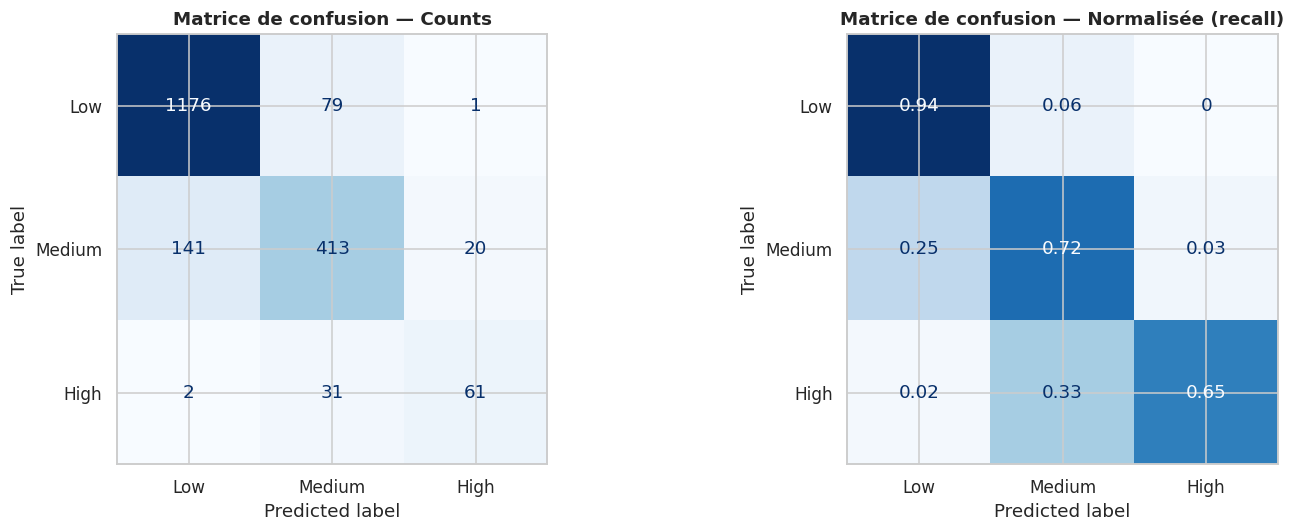

In [30]:
# Confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Counts
cm = confusion_matrix(y_val, best_pred_val)
disp = ConfusionMatrixDisplay(cm, display_labels=['Low', 'Medium', 'High'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Matrice de confusion — Counts', fontweight='bold')

# Normalised
cm_norm = confusion_matrix(y_val, best_pred_val, normalize='true')
disp_norm = ConfusionMatrixDisplay(cm_norm.round(2), display_labels=['Low', 'Medium', 'High'])
disp_norm.plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Matrice de confusion — Normalisée (recall)', fontweight='bold')

plt.tight_layout()
plt.show()

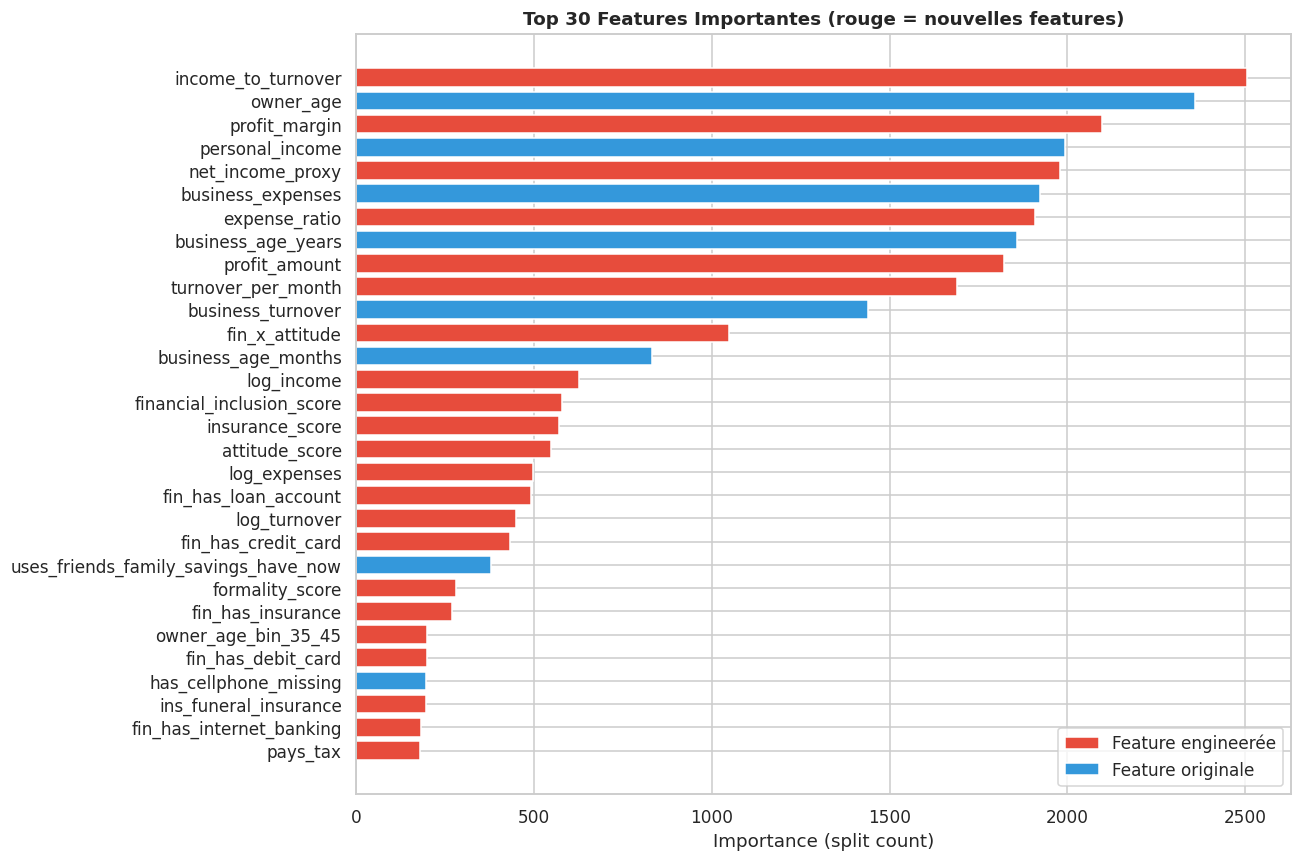

In [31]:
# Feature Importance (LightGBM)
fi = pd.DataFrame({
    'feature': X_train.columns,
    'importance': lgbm_model.feature_importances_
}).sort_values('importance', ascending=False)

top_n = 30
top_fi = fi.head(top_n)

engineered_kw = ['profit', 'expense_ratio', 'inclusion', 'insurance_score',
                 'attitude_score', 'formality', 'log_', 'income_to', 'net_income',
                 'fin_x', 'turnover_per', 'fin_', 'ins_', 'pos_', 'neg_',
                 'records_', 'pays_tax', 'owner_age_bin']

colors_fi = ['#e74c3c' if any(kw in f for kw in engineered_kw) else '#3498db'
             for f in top_fi['feature']]

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(top_fi['feature'][::-1], top_fi['importance'][::-1], color=colors_fi[::-1])
ax.set_title(f'Top {top_n} Features Importantes (rouge = nouvelles features)', fontweight='bold')
ax.set_xlabel('Importance (split count)')
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#e74c3c', label='Feature engineerée'),
                   Patch(facecolor='#3498db', label='Feature originale')]
ax.legend(handles=legend_elements)
plt.tight_layout()
plt.show()

In [32]:
# Cross-validation K-Fold
print("Cross-validation 5-Fold stratified...")

cv_model = LGBMClassifier(**lgbm_params)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_scores = cross_val_score(
    cv_model, X_all_encoded, y_all_encoded,
    cv=skf, scoring='f1_weighted', n_jobs=-1
)

print(f"\nCV Weighted F1 par fold : {cv_scores.round(4)}")
print(f"Moyenne : {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Cross-validation 5-Fold stratified...

CV Weighted F1 par fold : [0.8581 0.8786 0.862  0.8598 0.8702]
Moyenne : 0.8657 ± 0.0077


                      Weighted F1  vs Baseline (+0.88)
XGBoost                    0.8625              -0.0175
LightGBM (optimised)       0.8571              -0.0229
Ensemble Soft Voting       0.8548              -0.0252
CatBoost                   0.8335              -0.0465


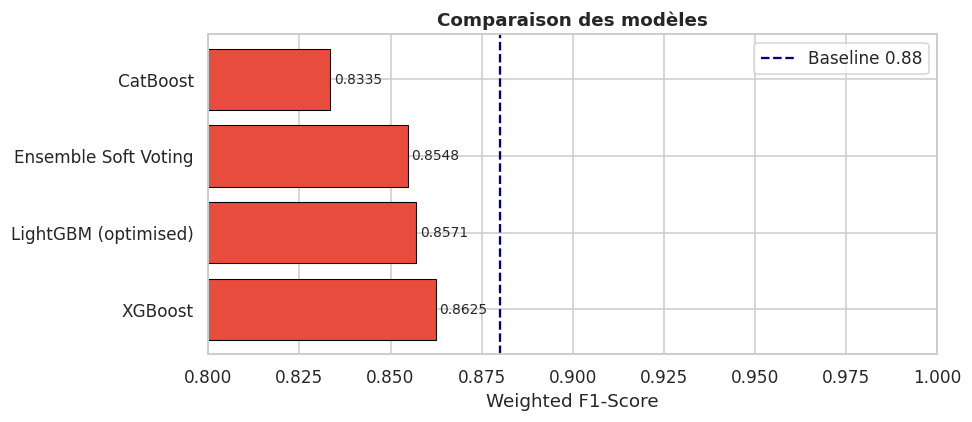

In [33]:
# Performance summary
results = {}

results['LightGBM (optimised)'] = f1_score(y_val, y_pred_lgbm, average='weighted')
if XGB_AVAILABLE:
    results['XGBoost'] = f1_score(y_val, y_pred_xgb, average='weighted')
if CB_AVAILABLE:
    results['CatBoost'] = f1_score(y_val, y_pred_cb, average='weighted')
if len(probas) > 1:
    results['Ensemble Soft Voting'] = f1_score(y_val, best_pred_val, average='weighted')

results_df = pd.DataFrame.from_dict(results, orient='index', columns=['Weighted F1'])
results_df = results_df.sort_values('Weighted F1', ascending=False)
results_df['vs Baseline (+0.88)'] = (results_df['Weighted F1'] - 0.88).round(4)
print(results_df.round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
colors_bar = ['#2ecc71' if v > 0.88 else '#e74c3c' for v in results_df['Weighted F1']]
ax.barh(results_df.index, results_df['Weighted F1'], color=colors_bar, edgecolor='black', linewidth=0.7)
ax.axvline(0.88, color='navy', linestyle='--', linewidth=1.5, label='Baseline 0.88')
ax.set_xlabel('Weighted F1-Score')
ax.set_title('Comparaison des modèles', fontweight='bold')
ax.legend()
ax.set_xlim(0.80, 1.0)
for i, v in enumerate(results_df['Weighted F1']):
    ax.text(v + 0.001, i, f'{v:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

# 8. Final training & Submission

In [34]:
# Train the best model on the entire train
print("Final training session on the entire train...")

final_model = LGBMClassifier(**lgbm_params)
final_model.fit(
    X_all_encoded, y_all_encoded,
    callbacks=[lgb.log_evaluation(period=-1)]
)

print("Training finished.")

Final training session on the entire train...
Training finished.


In [35]:
# Predictions for the test set
X_test_final = X_test_encoded.copy()

test_probas = [final_model.predict_proba(X_test_final)]

if XGB_AVAILABLE:
    xgb_final = XGBClassifier(
        objective='multi:softprob', num_class=3,
        n_estimators=xgb_model.best_iteration if hasattr(xgb_model, 'best_iteration') else 500,
        learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.7,
        eval_metric='mlogloss', n_jobs=-1, random_state=SEED, verbosity=0
    )
    xgb_final.fit(X_all_encoded, y_all_encoded, verbose=False)
    test_probas.append(xgb_final.predict_proba(X_test_final))

if CB_AVAILABLE:
    cb_final = CatBoostClassifier(
        iterations=cb_model.best_iteration_ if hasattr(cb_model, 'best_iteration_') else 500,
        learning_rate=0.05, depth=7, l2_leaf_reg=3,
        auto_class_weights='Balanced', random_seed=SEED, verbose=False
    )
    cb_final.fit(X_all_encoded, y_all_encoded)
    test_probas.append(cb_final.predict_proba(X_test_final))

# Average the probabilities

final_avg_proba = np.mean(test_probas, axis=0)
final_preds_encoded = np.argmax(final_avg_proba, axis=1)

# Decoding the predictions
final_preds = [inv_label_map[p] for p in final_preds_encoded]

print("Distribution of test predictions :")
unique, counts = np.unique(final_preds, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  {u}: {c} ({100*c/len(final_preds):.1f}%)")

Distribution of test predictions :
  High: 103 (4.3%)
  Low: 1649 (68.6%)
  Medium: 653 (27.2%)


In [36]:
# Save submission
submission = pd.DataFrame({
    'ID': test_df['ID'].values,
    'Target': final_preds
})

submission.to_csv('submission.csv', index=False)
print("File submission.csv saved.")
print(f"\nShape : {submission.shape}")
submission.head(10)

File submission.csv saved.

Shape : (2405, 2)


,ID,Target
0,ID_5EGLKX,Low
1,ID_4AI7RE,Low
2,ID_V9OB3M,Low
3,ID_6OI9DI,Medium
4,ID_H2TN8B,Low
5,ID_U8T7ZQ,Medium
6,ID_QQJ3A1,Low
7,ID_F5S4JD,Low
8,ID_CY2C11,Medium
9,ID_63XVFI,Low
